# Random Forest

A random forest combines many randomized decision trees.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [2]:
data=load_breast_cancer(as_frame=True); X,y=data.data,data.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
models={"Decision Tree":DecisionTreeClassifier(random_state=42),"Random Forest":RandomForestClassifier(n_estimators=200,max_features="sqrt",random_state=42,n_jobs=-1)}
rows=[]
for name,model in models.items():
 model.fit(X_train,y_train); rows.append({"model":name,"train_accuracy":model.score(X_train,y_train),"test_accuracy":model.score(X_test,y_test)})
pd.DataFrame(rows).round(4)

,model,train_accuracy,test_accuracy
0,Decision Tree,1.0,0.9123
1,Random Forest,1.0,0.9561


## Important parameters
- `n_estimators`: number of trees.
- `max_features`: features considered at each split.
- `max_depth`: maximum tree depth.
- `min_samples_leaf`: minimum samples in a leaf.

In [3]:
rows=[]
for n in [50,100,200]:
 model=RandomForestClassifier(n_estimators=n,max_features="sqrt",random_state=42,n_jobs=-1).fit(X_train,y_train)
 rows.append({"n_estimators":n,"train_accuracy":model.score(X_train,y_train),"test_accuracy":model.score(X_test,y_test)})
pd.DataFrame(rows).round(4)

,n_estimators,train_accuracy,test_accuracy
0,50,1.0,0.9561
1,100,1.0,0.9561
2,200,1.0,0.9561


## Feature importance

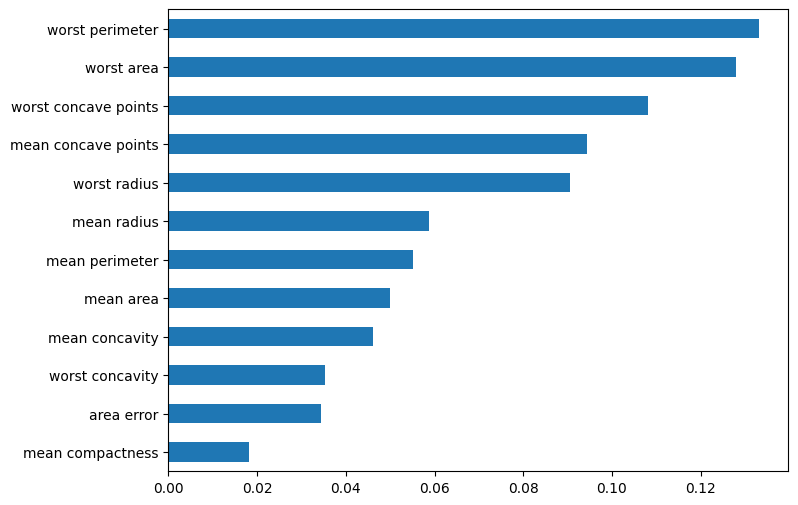

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [4]:
forest=models["Random Forest"]
importance=pd.Series(forest.feature_importances_,index=X.columns).sort_values().tail(12)
importance.plot(kind="barh",figsize=(8,6)); plt.show()
print(classification_report(y_test,forest.predict(X_test),target_names=data.target_names))